# Математички методи за машинско учење 2025/26
## Домаћи задатак број 2

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 01Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [28]:
import numpy as np
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt
from timeit import default_timer as timer
from math import comb
from scipy.spatial import ConvexHull
from matplotlib.path import Path

**Задатак 1.**
Полином трећег степена $P(x)$ задовољава следеће услове: 
$$P(0)=1, \quad P'(0)=0, \quad P(1)=2, \quad P''(1)=0.$$

а) Формирати систем линеарних једначина за непознате коефицијенте полинома $P(x) = ax^3+bx^2+cx+d$ и решити га аналитички или матрично.

(5 поена)

Iz uslova $P(0)=1$ važi:
$$d = 1$$

$P'(x) = 3ax^2 + 2bx + c$, pa iz uslova $P'(0)=0$ dobijamo:
$$c = 0$$

Iz uslova $P(1)=2$ važi:
$$a + b + c + d = 2$$

$P''(x) = 6ax + 2b$, pa iz uslova $P''(1)=0$ dobijamo:
$$6a + 2b = 0$$

Na osnovu $d=1$ и $c=0$, dobijamo:
$$a + b = 1, \quad 3a + b = 0$$

Oduzimanjem:
$$(3a+b) - (a+b) = 0 - 1 \;\;\Rightarrow\;\; 2a = -1 \;\;\Rightarrow\;\; a = -\tfrac{1}{2}$$

I na kraju:
$$b = 1 - a = \tfrac{3}{2}$$

Konačni polinom:

$$P(x) = -\tfrac{1}{2}x^3 + \tfrac{3}{2}x^2 + 1$$

б) Проверити добијени резултат. Приказати график полинома.

(5 поена)

Dobijeni polinom je  
$$P(x) = -\tfrac{1}{2}x^3 + \tfrac{3}{2}x^2 + 1.$$

Njegovi izvodi su:  
$$P'(x) = -\tfrac{3}{2}x^2 + 3x, \qquad P''(x) = -3x + 3.$$

Vrednosti u tačkama:
  $$P(0) = 1, \qquad P(1) = -\tfrac{1}{2} + \tfrac{3}{2} + 1 = 2.$$

Prvi izvod u nuli:
  $$P'(0) = 0.$$

Drugi izvod u jedinici:
  $$P''(1) = -3 + 3 = 0.$$

Svi zadati uslovi su zadovoljeni.

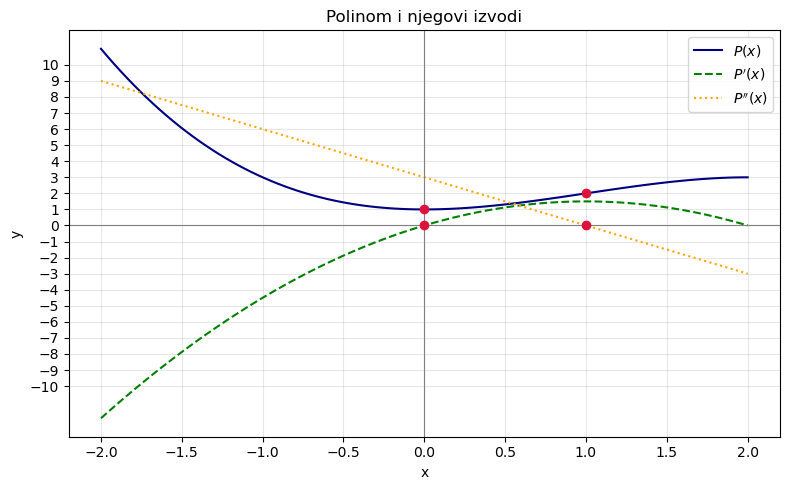

In [29]:
def P(x):
    return -0.5*x**3 + 1.5*x**2 + 1

def P_prim(x):
    return -1.5*x**2 + 3*x

def P_second(x):
    return -3*x + 3

x = np.linspace(-2, 2, 100)

y = P(x)
y1 = P_prim(x)
y2 = P_second(x)

points_x = np.array([0, 1])
points_y = P(points_x)

plt.figure(figsize=(8, 5))

plt.plot(x, y, label=r"$P(x)$", color="navy")
plt.plot(x, y1, label=r"$P'(x)$", color="green", linestyle="--")
plt.plot(x, y2, label=r"$P''(x)$", color="orange", linestyle=":")

plt.scatter(points_x, points_y, color="crimson", zorder=3)
plt.scatter(0, P_prim(0), color="crimson", zorder=3)
plt.scatter(1, P_second(1), color="crimson", zorder=3)

plt.axhline(0, color="gray", lw=0.8)
plt.axvline(0, color="gray", lw=0.8)
plt.yticks(np.arange(-10, 11, 1))

plt.grid(alpha=0.3)
plt.legend()
plt.title("Polinom i njegovi izvodi")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.show()

***

**Задатак 2.** Да ли постоји полином трећег степена који пролази кроз следеће тачке
$$\begin{array}{c||c|c|c|c|c|c}
x_k&1&-2&0&3&-1&7\\\hline
y_k&-2&-56&-2&4&-16&376
\end{array}.$$ 
Образложити свој одговор.

(10 поена)

Neka je polinom trećeg stepena:
$$P(x) = ax^3 + bx^2 + cx + d.$$

Iz tačke $(0,-2)$ dobijamo:
$$d = -2.$$

Iz tačke $(1,-2)$:
$$a + b + c + d = -2 \;\;\Rightarrow\;\; a + b + c = 0.$$

Iz tačke $(-1,-16)$:
$$-a + b - c + d = -16 \;\;\Rightarrow\;\; -a + b - c = -14.$$

Iz tačke $(3,4)$:
$$27a + 9b + 3c + d = 4 \;\;\Rightarrow\;\; 27a + 9b + 3c = 6.$$

Sada je potrebno rešiti postavljeni sistem jednačina. Sabiranjem jednačina $a + b + c = 0$ i $-a + b - c = -14$ dobijamo:
$$2b = -14 \;\;\Rightarrow\;\; b = -7$$

Zatim iz $a + b + c = 0$:
$$c = -a - b = -a + 7.$$

Zamenom u $27a+9b+3c=6$:
$$27a + 9(-7) + 3(-a+7) = 6 \;\;\Rightarrow\;\; 24a - 42 = 6 \;\;\Rightarrow\;\; a = 2$$

Dakle:
$$a=2,\quad b=-7,\quad c=5,\quad d=-2$$

Dobijeni polinom:

$$P(x) = 2x^3 - 7x^2 + 5x - 2$$

Provera za preostale tačke:

Za $x=-2$:  
$$P(-2) = 2 \cdot (-8) - 7 \cdot 4 + 5 \cdot (-2) - 2 = -56$$

Za $x=7$:  
$$P(7) = 2 \cdot 343 - 7 \cdot 49 + 5 \cdot 7 - 2 = 376$$

Dakle, traženi polinom trećeg stepena postoji:
$$P(x) = 2x^3 - 7x^2 + 5x - 2.$$

***

**Задатак 3.** Бернштајнови базни полиноми $B_{i,n}(t)$ степена $n$
 дефинисани су као 
 $$B_{i,n}(t)=\binom{n}{i}t^i(1-t)^{n-i},$$
 за $i=0,1,\dots,n.$
Ови полиноми чине основу за Безијерове криве које се користе у рачунарској графици и планирању путања у роботици.

**а)** За случај $n=3$ (кубни полиноми), написати експлицитне изразе за $B_{i,3}(t),\ i=0,1,2,3.$

(5 поена)

Za $i=0$:

$$B_{0,3}(t)={3 \choose 0}t^0(1-t)^3=(1-t)^3$$

$$ (1-t)^3=1-3t+3t^2-t^3 $$

Za $i=1$:

$$ B_{1,3}(t)={3 \choose 1}t^1(1-t)^2=3t(1-t)^2 $$

$$ (1-t)^2=1-2t+t^2 \quad \Rightarrow \quad 3t(1-2t+t^2)=3t-6t^2+3t^3 $$

Za $i=2$:

$$ B_{2,3}(t)={3 \choose 2}t^2(1-t)^1=3t^2(1-t) $$

$$ 3t^2(1-t)=3t^2-3t^3 $$

Za $i=3$:

$$ B_{3,3}(t)={3 \choose 3}t^3(1-t)^0=t^3 $$

Konačni rezultati:

$$ B_{0,3}(t)=1-3t+3t^2-t^3 $$

$$ B_{1,3}(t)=3t-6t^2+3t^3 $$

$$ B_{2,3}(t)=3t^2-3t^3 $$

$$ B_{3,3}(t)=t^3 $$

**б)** Формирати матрицу преласка $T$ из стандардне базе $\{,t,t^2,t^3\}$ у Бернштајнову базу $B_{i,3}(t),\ i=0,1,2,3.$ 

(5 поена)

Dobijeni Bernštajnovi polinomi su:
$$
\begin{aligned}
B_{0,3}(t) &= 1 - 3t + 3t^2 - t^3,\\
B_{1,3}(t) &= 3t - 6t^2 + 3t^3,\\
B_{2,3}(t) &= 3t^2 - 3t^3,\\
B_{3,3}(t) &= t^3.
\end{aligned}
$$

Matrica prelaska $T$ za koju važi $[p]_{(B)} = T \cdot [p]_{(\text{std})}$
se dobija tako što svaki element standardne baze izrazimo
kao linearnu kombinaciju Bernštajnovih polinoma.

1. Zapis polinoma $1$

$$
\begin{aligned}
B_{0,3} + B_{1,3} + B_{2,3} + B_{3,3}
&= (1 - 3t + 3t^2 - t^3) \\
&\quad + (3t - 6t^2 + 3t^3) \\
&\quad + (3t^2 - 3t^3) + t^3 \\
&= 1.
\end{aligned}
$$

$$
1 = B_{0,3} + B_{1,3} + B_{2,3} + B_{3,3}.
$$

2. Zapis polinoma $t$

$$
t = aB_{0,3} + bB_{1,3} + cB_{2,3} + dB_{3,3}.
$$

$$
t = \frac13 B_{1,3} + \frac23 B_{2,3} + B_{3,3}.
$$

3. Zapis polinoma $t^2$

$$
t^2 = aB_{0,3} + bB_{1,3} + cB_{2,3} + dB_{3,3}.
$$

$$
t^2 = \frac13 B_{2,3} + B_{3,3}.
$$

4. Zapis polinoma $t^3$

$$
t^3 = B_{3,3}.
$$

Koeficijenti ovih razlaganja čine kolone matrice prelaska $T$.

$$
T=
\begin{bmatrix}
1 & 0 & 0 & 0\\
1 & \frac13 & 0 & 0\\
1 & \frac23 & \frac13 & 0\\
1 & 1 & 1 & 1
\end{bmatrix}.
$$


In [30]:
# Provera: neka je dat polinom 3t^3 - t^2 + t - 2
# njegove koordinate u standardnoj bazi {1, t, t^2, t^3} su sledece: 
vec = np.array([-2, 1, -1, 3])
T = np.array([[1, 0,   0,   0],
              [1, 1/3, 0,   0],
              [1, 2/3, 1/3, 0],
              [1, 1,   1,   1]])

T@vec

array([-2.        , -1.66666667, -1.66666667,  1.        ])

Dobijene koordinate u Bernštajnovoj bazi su 
$\begin{bmatrix}-2 & -\frac{5}{3} & -\frac{5}{3} & 1\end{bmatrix}$. 

Ako izračunamo 
$$
-2\,B_{0,3}(t) - \frac{5}{3}\,B_{1,3}(t) - \frac{5}{3}\,B_{2,3}(t) + 1\,B_{3,3}(t),
$$ 
dobićemo polinom 
$$
3t^3 - t^2 + t - 2,
$$ 
a to je polazni polinom, što znači da je matrica prelaska ispravna.


**в)** Проверити програмски да ли важи особина партиције јединице: 
$$\sum_{i=0}^3B_{i,3}(t)=1,$$
за низ вредности $t\in[0,1].$

(5 поена)

In [31]:
t = np.linspace(0, 1, 100)

B = np.array([
    (1 - t)**3,
    3 * t * (1 - t)**2,
    3 * t**2 * (1 - t),
    t**3
])

sum_B = np.sum(B, axis=0)
print(sum_B)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1.]


Može se videti da osobina particije jedinice važi.

**г)** У Python-у графички приказати ове 4 базне функције на интервалу $t\in[0,1]$ на једном графику.

(5 поена)

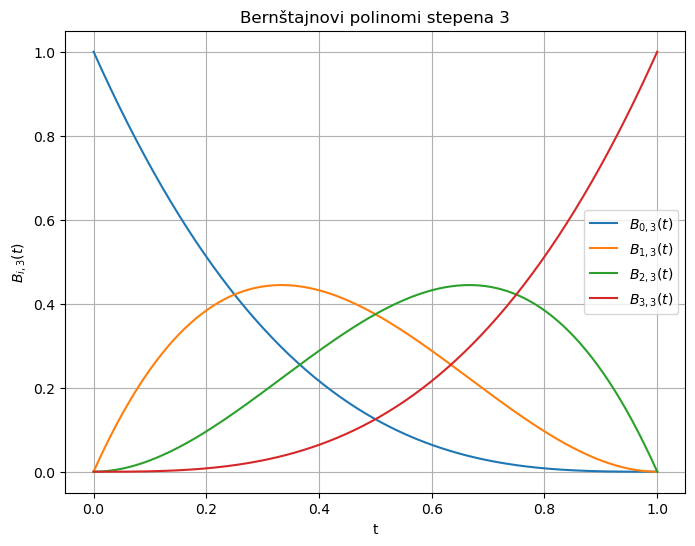

In [32]:
def B(i, n, t):
    return comb(n, i) * (t**i) * ((1-t)**(n-i))

n = 3
t = np.linspace(0, 1, 200)

plt.figure(figsize=(8,6))
for i in range(n+1):
    plt.plot(t, B(i, n, t), label=fr"$B_{{{i},{n}}}(t)$")

plt.title("Bernštajnovi polinomi stepena 3")
plt.xlabel("t")
plt.ylabel(fr"$B_{{i,{n}}}(t)$")
plt.legend()
plt.grid(True)
plt.show()

***

**Задатак 4.** 
Безијерове криве се најчешће користе за апроксимацију (где крива пролази близу, али не нужно кроз контролне тачке). Међутим, у роботици и анимацији често је потребно решити проблем **интерполације**: пронаћи криву која пролази **тачно** кроз задати скуп тачака (нпр. робот мора да погоди тачне чекпоинте).

Тачка на **кубној** Безијеровој кривој $B(t)$ за параметар $t \in [0, 1]$ одређена је са 4 контролне тачке ($P_0, P_1, P_2, P_3$) помоћу Бернштајнових полинома:
$$B(t) = (1-t)^3 P_0 + 3t(1-t)^2 P_1 + 3t^2(1-t) P_2 + t^3 P_3.$$

**а) Имплементација (Векторизовани De Casteljau):**
Написати функцију `de_casteljau(control_points, t)` која коришћењем **троугаоне итеративне шеме** рачуна координате тачке на кривој. Ова функција ће вам служити за исцртавање криве након што одредите непознате контролне тачке.

Овај алгоритам је **троугаони поступак** (сличан Невиловом). Ако су $\beta_0^{(0)}, \dots, \beta_n^{(0)}$ контролне тачке, тада се тачка на кривој (за конкретно $t$) рачуна итеративним "линеарним" комбинацијама:
$$\beta_i^{(k)} = (1-t)\beta_i^{(k-1)} + t\beta_{i+1}^{(k-1)},\qquad i=0,1,\dots,n-k,$$
где је $\beta_i^{(0)}$ почетна координата $i$-те контролне тачке. Коначна тачка на кривој је $\beta_0^{(n)},$ где је $n$ степен криве. Дакле, са сваком итерацијом алгоритма (бројач је $k$) се број контролних тачака $\beta_0^{(k)}, \dots, \beta_{n-k}^{(k)}$ смањује за 1.

Функција `de_casteljau(control_points, t)` прима улазне податке:
*   `control_points`: матрицу контролних тачака димензије $(n+1) \times 2$.
*   `t`: **низ** временских тренутака (вектор димензије $M$).


Формула за ажурирање низа тачака у $k$-том кораку гласи:
$$\beta^{(k)} = (1-t) \cdot \beta^{(k-1)}[:-1] + t \cdot \beta^{(k-1)}[1:]$$
где је $\beta^{(0)}$ почетни низ контролних тачака. Коначан резултат је $\beta^{(n)}$.

Функција треба да израчуна координате тачака на кривој за све вредности $t$ **истовремено**. 
**Захтев:** У имплементацији је дозвољено користити **само једну петљу** (петљу која иде по слојевима редукције, тј. по степену криве). Није дозвољено користити петљу за пролазак кроз низ `t`.

(5 поена)

#### 1. Интуиција иза формуле 
De Casteljau алгоритам ради на принципу узастопне линеарне интерполације. Замислите да формула:
$$\beta_i^{(k)} = (1-t)\beta_i^{(k-1)} + t\beta_{i+1}^{(k-1)}$$
значи: *"Нова тачка се налази на дужи између две старе тачке, померена за проценат $t$ ка другој тачки."*

In [33]:
def de_casteljau(control_points, t):
    n = control_points.shape[0] - 1
    M = t.shape[0]
    d = control_points.shape[1]

    # kreiraju se kopije matrice kontrolnih tacaka,
    # da bi moglo istovremeno da se obavlja izracunavanje za sve vrednosti u t
    beta = np.tile(control_points[None, :, :], (M, 1, 1))

    for k in range(1, n+1):
        # vrsi se dodavanje novih osa zbog broadcastinga vektora t preko 3D niza beta
        beta = (1 - t)[:, None, None] * beta[:, :-1, :] + t[:, None, None] * beta[:, 1:, :]
    
    return beta[:, 0, :]

**б) Интерполација (Инверзни проблем):**

Робот мора да прође тачно кроз 4 задате тачке у одређеним временским тренуцима:
*   $D_0 = (0, 0)$ у $t=0$
*   $D_1 = (2, 4)$ у $t=1/3$
*   $D_2 = (8, 4)$ у $t=2/3$
*   $D_3 = (10, 0)$ у $t=1$

Ваш задатак је да пронађете непознате **контролне тачке** $P_0, P_1, P_2, P_3$ које дефинишу овакву криву.
1.  На основу својства крајњих тачака, одредити $P_0$ и $P_3$.
2.  За $t=1/3$ и $t=2/3$, поставити систем линеарних једначина по непознатим тачкама $P_1$ и $P_2$ користећи формулу за $B(t)$.
3.  Решити систем (матрично или аналитички) и израчунати координате тачака $P_1$ и $P_2$.

(5 поена)

**Разлика између $P$ и $D$:**
*   $P_i$ су **контролне тачке** (Control Points). Оне дефинишу облик, али крива (обично) не пролази кроз $P_1$ и $P_2$.
*   $D_i$ су **тачке података** (Data Points). Крива мора проћи тачно кроз њих.

**Како поставити систем једначина (Део б):**
Формула за криву је:
$$B(t) = (1-t)^3 P_0 + \mathbf{3t(1-t)^2 P_1} + \mathbf{3t^2(1-t) P_2} + t^3 P_3$$
Знамо да је $P_0 = D_0$ и $P_3 = D_3$. Непознате су нам $P_1$ и $P_2$.
Када убацимо услов да крива пролази кроз $D_1$ у тренутку $t=1/3$, добијамо:
$$D_1 - (1-t)^3 P_0 - t^3 P_3 = 3t(1-t)^2 \mathbf{P_1} + 3t^2(1-t) \mathbf{P_2}$$
(за $t=1/3$).

Ово води ка систему облика $\mathbf{A}\mathbf{x} = \mathbf{b}$, где је вектор непознатих $\mathbf{x} = [P_1, P_2]^T$. Матрица $\mathbf{A}$ садржи коефицијенте који зависе од $t$, а вектор $\mathbf{b}$ садржи познате тачке $D$ и $P_0, P_3$.

$P_0 = D_0 = (0,0)$

$P_3 = D_3 = (10,0)$

Za $t=\tfrac{1}{3}$ važi
$$
D_1 - (1-t)^3 P_0 - t^3 P_3 = 3t(1-t)^2 P_1 + 3t^2(1-t) P_2.
$$
Bernštajnovi polinomi za $t=\tfrac{1}{3}$:
$$
(1-t)^3=\tfrac{8}{27}, \quad t^3=\tfrac{1}{27}, \quad 3t(1-t)^2=\tfrac{4}{9}, \quad 3t^2(1-t)=\tfrac{2}{9}.
$$
Dakle,
$$
D_1 - \tfrac{8}{27} P_0 - \tfrac{1}{27} P_3
= \tfrac{4}{9} P_1 + \tfrac{2}{9} P_2,
$$
odnosno, znajući $P_0=(0,0)$ i $P_3=(10,0)$ imamo:
$$
\left(2,4\right) - \left(\tfrac{10}{27},0\right) = \tfrac{4}{9} P_1 + \tfrac{2}{9} P_2,
$$
$$
\left(\tfrac{44}{27},\,4\right) = \tfrac{4}{9} P_1 + \tfrac{2}{9} P_2. \quad \text{(I)}
$$

Na isti način postavljamo jednačinu za $t=\tfrac{2}{3}$:
$$
(1-t)^3=\tfrac{1}{27}, \quad t^3=\tfrac{8}{27}, \quad 3t(1-t)^2=\tfrac{2}{9}, \quad 3t^2(1-t)=\tfrac{4}{9},
$$
pa sledi
$$
D_2 - \tfrac{1}{27} P_0 - \tfrac{8}{27} P_3
= \tfrac{2}{9} P_1 + \tfrac{4}{9} P_2,
$$
odnosno
$$
\left(8,4\right) - \left(\tfrac{80}{27},0\right) = \tfrac{2}{9} P_1 + \tfrac{4}{9} P_2,
$$
$$
\left(\tfrac{136}{27},\,4\right) = \tfrac{2}{9} P_1 + \tfrac{4}{9} P_2. \quad \text{(II)}
$$

Dakle, dobijeni sistem jednačina je:
$$
\tfrac{4}{9} P_1 + \tfrac{2}{9} P_2 = \left(\tfrac{44}{27},\,4\right)
$$

$$
\tfrac{2}{9} P_1 + \tfrac{4}{9} P_2 = \left(\tfrac{136}{27},\,4\right)
$$

In [34]:
# rešavanje sistema matrično
A = np.array([
    [4/9, 2/9],
    [2/9, 4/9]
])

# desna strana za x-koordinate
b_x = np.array([44/27, 136/27])

# desna strana za y-koordinate
b_y = np.array([4, 4])

P_x = np.linalg.solve(A, b_x)
P_y = np.linalg.solve(A, b_y)

P1 = (P_x[0], P_y[0])
P2 = (P_x[1], P_y[1])

print("P1 = ", P1)
print("P2 = ", P2)

P1 =  (np.float64(-2.666666666666667), np.float64(6.000000000000001))
P2 =  (np.float64(12.666666666666668), np.float64(6.0))


Konačno:
$$
P_0=(0,0), \quad P_1=\left(-\tfrac{8}{3},\,6\right), \quad P_2=\left(\tfrac{38}{3},\,6\right), \quad P_3=(10,0).
$$

**в) Визуелизација:**
Приказати на истом графику:
1.  Задате тачке $D_0, \dots, D_3$ (као црвене крстиће) – циљеви кроз које робот пролази.
2.  Израчунате контролне тачке $P_0, \dots, P_3$ (као плаве кружиће) и њихов полигон (испрекидана линија).
3.  Резултујућу криву (користећи функцију из дела а).

(5 поена)

На крајњем графику ћете приметити да су израчунате контролне тачке $P_1$ и $P_2$ често "шире" или даље од тачака пролаза $D_1$ и $D_2$. То је зато што контролне тачке морају снажно да "вуку" криву како би је натерале да прође кроз жељене чекпоинте.

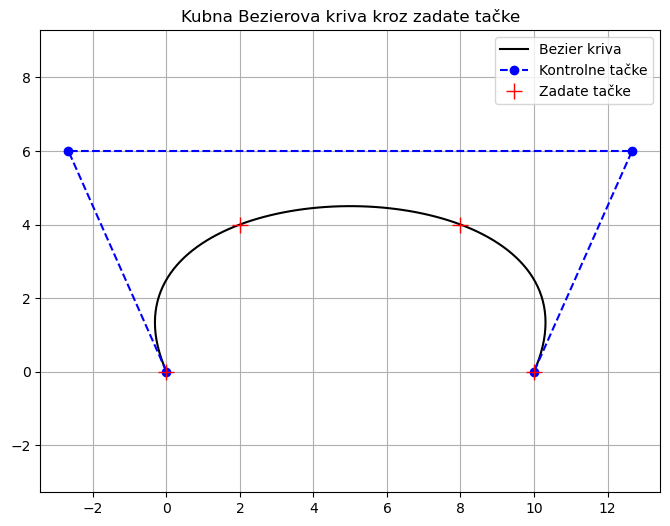

In [35]:
control_points = np.array([[0, 0], 
                           [-8/3, 6], 
                           [38/3, 6], 
                           [10, 0]])

data_points = np.array([[0, 0], 
                        [2, 4], 
                        [8, 4], 
                        [10, 0]])

t = np.linspace(0, 1, 100)
curve_points = de_casteljau(control_points, t)

plt.figure(figsize=(8,6))

plt.plot(curve_points[:,0], curve_points[:,1], 'k-', label='Bezier kriva')
plt.plot(control_points[:,0], control_points[:,1], 'bo--', label='Kontrolne tačke')
plt.plot(data_points[:,0], data_points[:,1], 'r+', markersize=12, label='Zadate tačke')

plt.legend()
plt.axis('equal')
plt.grid(True)
plt.title("Kubna Bezierova kriva kroz zadate tačke")
plt.show()

г) **Примена (Планирање путање):**
Робот треба да стигне од $Start(0, 0)$ до $Goal(10, 10)$, заобилазећи препреку на $(5, 5)$. Дефинисати 4 контролне тачке ($P_0, P_1, P_2, P_3$) тако да путања заобиђе препреку. Израчунати и нацртати путању за $t \in [0, 1]$.

Jedan mogući izbor kontrolnih tačaka:
$$
P_0=(0,0) \quad
P_1=(0,6) \quad
P_2=(6,10) \quad
P_3=(10,10)
$$

Računanje i crtanje putanje se obavlja u delu $(d)$, da ne bi bilo dupliranja istog koda i prikaza.

д) **Визуелизација:** Приказати путању, контролне тачке и њихов конвексни омотач (полигон). Проверити да ли путања излази из оквира овог полигона.

(10 поена)

Putanja je potpuno unutar konveksnog omotača


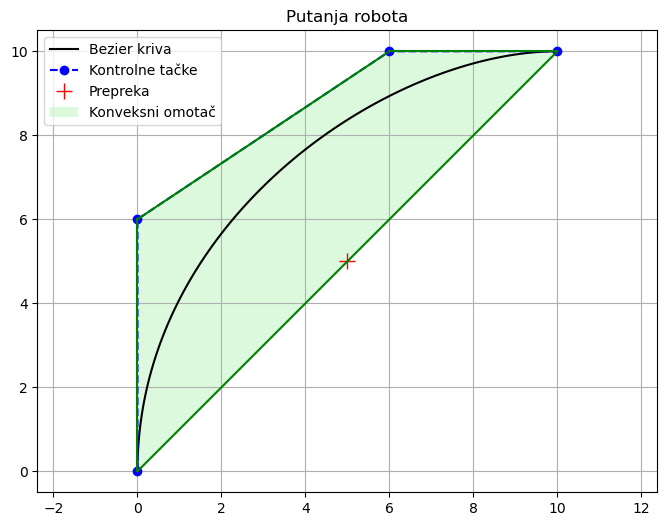

In [36]:
control_points = np.array([[0, 0], 
                           [0, 6], 
                           [6, 10], 
                           [10, 10]])

data_points = np.array([5, 5])

t = np.linspace(0, 1, 100)
curve_points = de_casteljau(control_points, t)
hull = ConvexHull(control_points)

plt.figure(figsize=(8,6))

plt.plot(curve_points[:,0], curve_points[:,1], 'k-', label='Bezier kriva')
plt.plot(control_points[:,0], control_points[:,1], 'bo--', label='Kontrolne tačke')
plt.plot(data_points[0], data_points[1], 'r+', markersize=12, label='Prepreka')

for simplex in hull.simplices:
    plt.plot(control_points[simplex,0], control_points[simplex,1], 'g-')

plt.fill(control_points[hull.vertices,0], control_points[hull.vertices,1],
         facecolor='lightgreen', alpha=0.3, label='Konveksni omotač')

hull_polygon = control_points[hull.vertices]
path = Path(hull_polygon)

inside = path.contains_points(curve_points, radius=1e-9)

if np.all(inside):
    print("Putanja je potpuno unutar konveksnog omotača")
else:
    print("Putanja izlazi iz konveksnog omotača")

plt.legend()
plt.axis('equal')
plt.grid(True)
plt.title("Putanja robota")
plt.show()

***

**Задатак 5.**
У машинском учењу и обради слике, често је потребно утврдити колико су две слике (или два дела слике) слични. Скаларни производ матрица дефинисан преко трага:
$$\langle A, B \rangle = \text{tr}(A^T B)$$
нам омогућава да дефинишемо **Косинусну сличност** између матрица $A$ и $B$:
$$\text{Sim}_{cos}(A, B) = \frac{\text{tr}(A^T B)}{\|A\|_F \|B\|_F}$$
Где је $\|A\|_F = \sqrt{\text{tr}(A^T A)}$ Фробенијусова норма. Ова мера враћа вредност у опсегу $[-1, 1]$ (за ненегативне пикселе $[0, 1]$).

Поред косинусне сличности, често се користи и **Еуклидско растојање** (L2 дистанца):
$$\text{Dist}_{L2}(A, B) = \|A - B\|_F$$

**Циљ:** Имплементирати ове мере, упоредити их и применити за проналажење објеката на слици (*Template Matching*).

**а) Функција:** Написати функцију `matrix_cosine_similarity(A, B)` користећи `np.trace`.

(5 поена)

In [37]:
def matrix_cosine_similarity(A, B):
    numerator = np.trace(A.T@B)
    fro_norm_A = np.sqrt(np.trace(A.T@A))
    fro_norm_B = np.sqrt(np.trace(B.T@B))
    
    if fro_norm_A == 0 or fro_norm_B == 0:
        return 0.0
    
    return numerator / (fro_norm_A * fro_norm_B)

**Припрема података:**

Покренути код испод за учитавање слике и припрему *grayscale* матрице:

In [38]:
import scipy.datasets as scd
import cv2

(768, 1024)


Text(0.5, 1.0, 'Originalna slika')

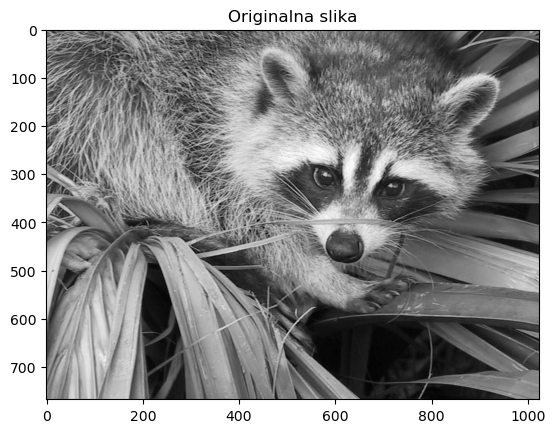

In [39]:
rakun=scd.face()
sk_vredn=rakun/255
rakun_gray = sk_vredn @ [0.2126, 0.7152, 0.0722]
print(rakun_gray.shape)
plt.imshow(rakun_gray, cmap="gray");
plt.title("Originalna slika")

**б) Идентитет:** Програмски потврдити да је $\|T\|_F^2 = \text{tr}(T^T T)$ (уз толеранцију, нпр. `1e-10`):.

(5 поена)

In [40]:
m=5
n=5
T = np.random.randint(low=0, high=10, size=(m, n))
print(T)

fro_norm_squared = np.linalg.norm(T, 'fro')**2
trace = np.trace(T.T@T)
print(np.isclose(fro_norm_squared, trace, atol=1e-10))

[[8 1 9 6 3]
 [8 1 0 4 5]
 [7 6 4 5 6]
 [8 0 0 2 4]
 [1 2 9 2 9]]
True


**в) Template Matching:**

1.  Исећи део слике (нпр. њушку) као шаблон $T$ (*template*).
2.  Исећи други део исте величине (нпр. лишће) као шум  $N$ (*noise*).
3.  Израчунати Косинусну сличност за парове $(T, T)$ и $(T, N)$.
4.  Израчунати L2 дистанцу за парове $(T, T)$ и $(T, N)$.
5.  Дискусија: Упоредити резултате. Која вредност указује на "идентичност" код косинусне сличности, а која код L2 дистанце?


(5 поена)

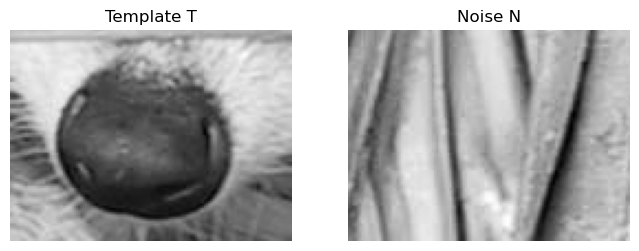

Kosinusna slicnost za (T, T) 1.0
Kosinusna slicnost za (T, N) 0.8848628201926535
L2 distanca za (T, T) 0.0
L2 distanca za (T, N) 38.908232714405614


In [41]:
def matrix_euclidean_distance(A, B):
    return np.linalg.norm(A - B, 'fro')

T = rakun_gray[400:496, 560:688] # 96, 128
N = rakun_gray[600:696, 50:178]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(T, cmap="gray")
axes[0].set_title("Template T")
axes[0].axis("off")

axes[1].imshow(N, cmap="gray")
axes[1].set_title("Noise N")
axes[1].axis("off")
plt.show()

print("Kosinusna slicnost za (T, T)", matrix_cosine_similarity(T, T))
print("Kosinusna slicnost za (T, N)", matrix_cosine_similarity(T, N))
print("L2 distanca za (T, T)", matrix_euclidean_distance(T, T))
print("L2 distanca za (T, N)", matrix_euclidean_distance(T, N))

Kod Kosinusne sličnosti na "identičnost" ukazuje vrednost $1$, dok je kod L2 distance to vrednost $0$. 

**г) Матрица сличности и Кластеризација:**

1.  Исећи **5 различитих делова** $P_i$ (patches) димензија $50 \times 50$:
    *   3 дела која захватају сличну текстуру (нпр. крзно).
    *   2 дела која захватају позадину (лишће).
    *   Сачувати их у листу `patches`.
2.  Креирати **Матрицу сличности** $S$ ($5 \times 5$), где је $S_{i,j}$ косинусна сличност између $P_i$ и $P_j$.
3.  Приказати матрицу користећи `heatmap` или `imshow`.
4.  **Кластеризација (Дендрограм):** Приказати хијерархијско груписање ових делова (користећи `scipy.cluster.hierarchy`). Да ли дендрограм исправно групише делова крзна одвојено од делова лишћа?


(5 поена)

In [42]:
from scipy.cluster.hierarchy import dendrogram, linkage
# Претворити матрицу сличности у дистанцу (1 - сличност) за кластеризацију

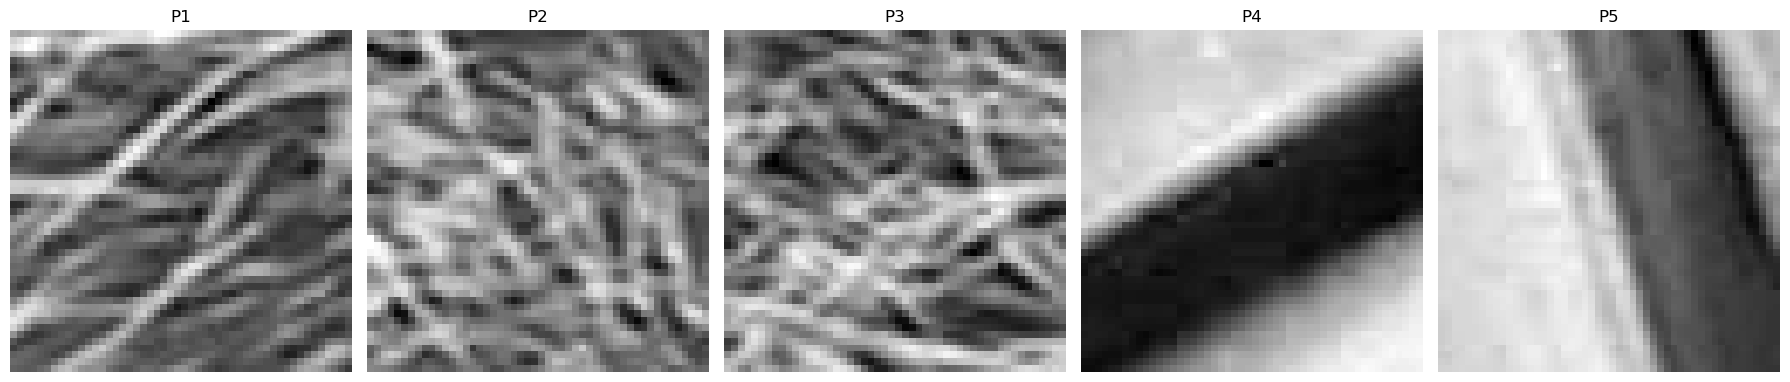

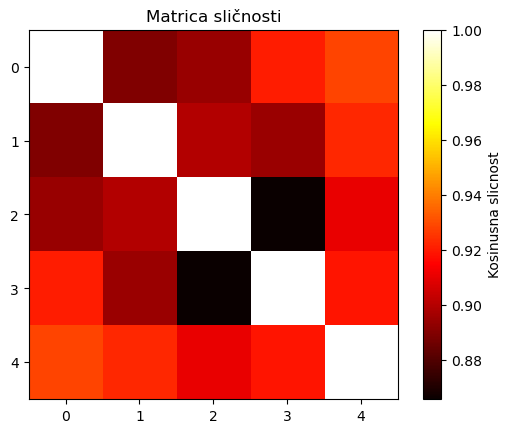

In [43]:
# krzno
P1 = rakun_gray[25:75, 50:100]
P2 = rakun_gray[25:75, 280:330]
P3 = rakun_gray[150:200, 280:330]

# lišće
P4 = rakun_gray[100:150, 970:1020]
P5 = rakun_gray[650:700, 350:400]

patches = [P1, P2, P3, P4, P5]
n=len(patches)

fig, axes = plt.subplots(1, n, figsize=(18, 4))
for i, ax in enumerate(axes):
    ax.imshow(patches[i], cmap="gray")
    ax.set_title(f"P{i+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

S = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        S[i, j] = matrix_cosine_similarity(patches[i], patches[j])

plt.imshow(S, cmap="hot", interpolation="nearest")
plt.colorbar(label="Kosinusna slicnost")
plt.title("Matrica sličnosti")
plt.show()

Text(0.5, 1.0, 'Груписање делова слике')

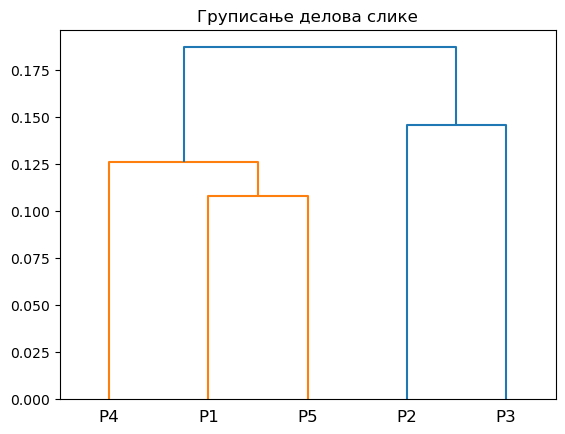

In [44]:
Z = linkage(1 - S, 'ward')
plt.figure()
dendrogram(Z, labels=["P1", "P2", "P3", "P4", "P5"])
plt.title("Груписање делова слике")

Dendrogram u ovom slučaju ne grupiše ispravno delove krzna odvojeno od delova lišća. Vidimo da je P1 (koji je krzno) grupisan zajedno sa P4 i P5 (koji su lišće).

**д) Визуелизација: "Sliding Window" претрага (Heatmap)**

Ово је примитиван облик детекције објеката. Желимо да пронађемо где се одређени део налази на слици.

1.  Изаберите један део слике као **Template** $T$ (нпр. њушка ракуна).
2.  Имплементирати алгоритам **клизног прозора (sliding window)**:
    *   Пролазити кроз оригиналну слику (или мањи регион ради брзине).
    *   У сваком кораку исећи део слике $W$ исте величине као $T$.
    *   Израчунати сличност између $W$ и $T$.
3.  Резултат чувати у новој матрици (мапи сличности).
4.  Приказати оригиналан $T$ и добијену **мапу сличности (heatmap)**. Најсветлија тачка на мапи треба да одговара позицији шаблона на слици.
5. **OpenCV имплементација:** Употребити функцију `cv2.matchTemplate` (са методом `TM_CCOEFF_NORMED`) да добијете мапу сличности.
3.  Приказати обе мапе једну поред друге. Да ли ваша имплементација даје сличан резултат као оптимизована OpenCV функција?

(5 поена)

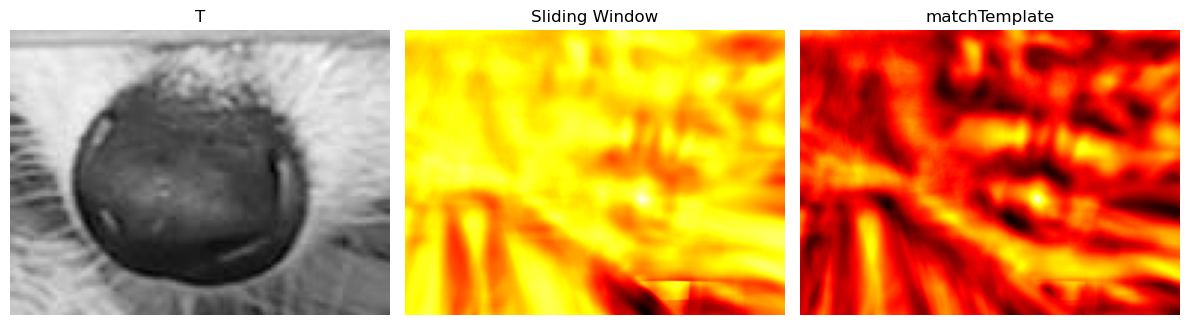

In [45]:
def sliding_window(image, template, stride_x=1, stride_y=1):
    h, w = template.shape
    H, W = image.shape
    
    out_h = (H - h) // stride_y + 1
    out_w = (W - w) // stride_x + 1
    
    similarity_map = np.zeros((out_h, out_w))
    
    for i in range(0, H - h + 1, stride_y):
        for j in range(0, W - w + 1, stride_x):
            window = image[i:i+h, j:j+w]
            sim = matrix_cosine_similarity(window, template)
            similarity_map[i // stride_y, j // stride_x] = sim
    
    return similarity_map

T = rakun_gray[400:496, 560:688] # 96, 128
similarity_map = sliding_window(rakun_gray, T, stride_x=2, stride_y=2)

result_cv = cv2.matchTemplate(rakun_gray.astype(np.float32),
                              T.astype(np.float32),
                              cv2.TM_CCOEFF_NORMED)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(T, cmap="gray")
axes[0].set_title("T")
axes[0].axis("off")

axes[1].imshow(similarity_map, cmap="hot")
axes[1].set_title("Sliding Window")
axes[1].axis("off")

axes[2].imshow(result_cv, cmap="hot")
axes[2].set_title("matchTemplate")
axes[2].axis("off")

plt.tight_layout()
plt.show()

Rezultati su slični. Na obe mape najsvetlija tačka odgovara poziciji T na originalnoj slici. OpenCV metoda sa parametrom `TM_CCOEFF_NORMED` oduzima srednju vrednost (vrši normalizaciju), što znači da je manje osetljiva na svetlije/tamnije regione. Sa druge strane, napisana implementacija Sliding Window tehnike ne oduzima srednju vrednost, pa zbog toga ne daje rezultate kao OpenCV metoda.

**ђ) Нумеричка стабилност и Нормализација (Zero-Centering)**

Сирове вредности пиксела могу заварати косинусну сличност (нпр. веома светао и веома таман део могу имати високу сличност ако су им вектори колинеарни).
Да бисмо ово решили, уводимо **нормализацију одузимањем средње вредности** (Zero-centering):
$$A_{norm} = A - \text{mean}(A)$$

1.  Модификовати функцију за косинусну сличност тако да прво "центрира" обе матрице (одузме њихов просек: $A - \text{mean}(A)$) пре рачунања трага. Ово је еквивалентно *Пирсоновој корелацији*.
2.  **Експеримент:** Искористити исту листу `patches` из дела **(г)**. Поново израчунати **Матрицу сличности** користећи нову (центрирану) функцију.
3.  **Визуелизација:** Приказати нову матрицу као *heatmap*.
4.  **Дискусија:** Упоредите овај *heatmap* са оним из дела (г). Да ли су контрасти између група (крзно vs позадина) сада израженији? Зашто је центрирање важно када поредимо текстуре које могу бити различито осветљене?

(5 поена)

In [46]:
def matrix_cosine_similarity_v2(A, B):
    A = A - np.mean(A)
    B = B - np.mean(B)
    numerator = np.trace(A.T@B)
    fro_norm_A = np.sqrt(np.trace(A.T@A))
    fro_norm_B = np.sqrt(np.trace(B.T@B))
    
    if fro_norm_A == 0 or fro_norm_B == 0:
        return 0.0
    
    return numerator / (fro_norm_A * fro_norm_B)

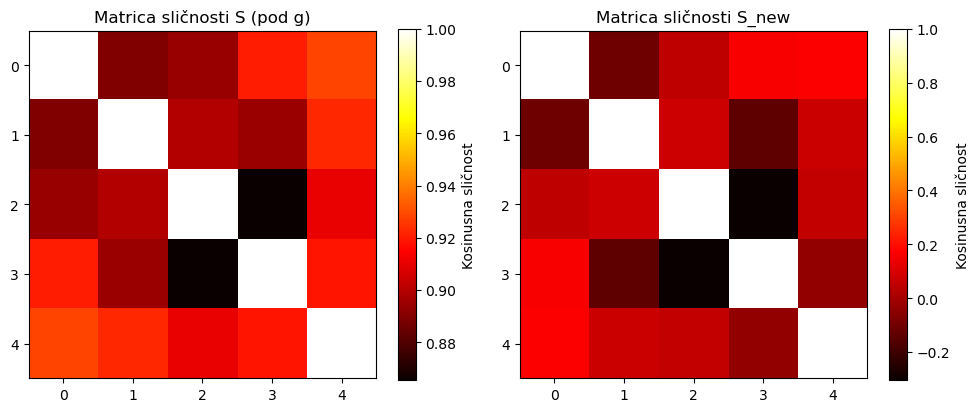

Matrica S:
 [[1.    0.889 0.894 0.92  0.928]
 [0.889 1.    0.899 0.895 0.922]
 [0.894 0.899 1.    0.866 0.91 ]
 [0.92  0.895 0.866 1.    0.919]
 [0.928 0.922 0.91  0.919 1.   ]]
Matrica S_new:
 [[ 1.    -0.105  0.052  0.16   0.17 ]
 [-0.105  1.     0.075 -0.14   0.072]
 [ 0.052  0.075  1.    -0.303  0.057]
 [ 0.16  -0.14  -0.303  1.    -0.038]
 [ 0.17   0.072  0.057 -0.038  1.   ]]


In [47]:
S_new = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        S_new[i, j] = matrix_cosine_similarity_v2(patches[i], patches[j])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

im1 = axes[0].imshow(S, cmap="hot", interpolation="nearest")
axes[0].set_title("Matrica sličnosti S (pod g)")
fig.colorbar(im1, ax=axes[0], label="Kosinusna sličnost")

im2 = axes[1].imshow(S_new, cmap="hot", interpolation="nearest")
axes[1].set_title("Matrica sličnosti S_new")
fig.colorbar(im2, ax=axes[1], label="Kosinusna sličnost")

plt.tight_layout()
plt.show()

print("Matrica S:\n", np.round(S,3))
print("Matrica S_new:\n", np.round(S_new,3))

Može se primetiti da se kod stare matrice S vrednosti kreću otprilike u opsegu od $0.86$ do $1.0$, dok se kod nove matrice S_new vrednosti kreću u opsegu od $-0.3$ do $1.0$. Kontrasti između grupa (krzno vs pozadina) su dosta izraženiji. Kod stare matrice sve vrednosti su bliske jedinici, a kod nove vidimo da postoje i vrednosti oko nule ali i neke negativne.

Centriranje je važno jer uklanja uticaj različite osvetljenosti i omogućava da se porede same teksture, bez da svetlost ima jak uticaj na ishod poređenja.

**е) Примена: Image Retrieval концепт**

Замислите да имате базу од 1000 слика. Како бисте нашли слике најсличније упитној слици $Q$?

1.  (Теоријски део): Објаснити како бисте користили косинусну сличност и концепт из дела (а) да рангирате слике из базе по релевантности за упит $Q$.
2.  Која је предност косинусне сличности над Еуклидском дистанцом ако су слике различите осветљености (нпр. једна је тамнија, друга светлија)?

(15 поена)

1. Na osnovu koncepta iz dela $(a)$, ideja bi bila da se za upitnu sliku $Q$ izračuna kosinusna sličnost sa svim slikama iz baze ponaosob. Nakon toga, potrebno bi bilo izvršiti rangiranje dobijenih rezultata. Pošto realne slike sadrže samo nenegativne piksele, dobijene vrednosti kosinusne sličnosti će biti u opsegu $[0,1]$. Što je dobijena vrednost bliža $1$, to su te dve slike sličnije, a što je bliža $0$ one su različitije. Nakon što su dobijeni rezultati sortirani, mogli bismo da vidimo koja slika je najsličnija upitnoj slici $Q$.
2. Prednost kosinusne sličnosti u odnosu na Euklidsku distancu je ta što je kosinusna sličnost manje osetljiva na promenu osvetljenja slike. Ako imamo osnovnu sliku, i sliku koja je ista kao ta osnovna, samo joj je promenjena osvetljenost (svetlija je ili tamnija u odnosu na osnovnu), kosinusna sličnost će idalje davati rezultate bliske $1$, što ukazuje na to da su slike slične, dok bi Euklidska distanca bila veća, što bi nas navelo da mislimo da su slike različite, a ustvari im je struktura ista. To možemo da vidimo i na sledećem primeru: kreirana je zatamnjena verzija slike iz dela pod $(a)$, a zatim su izračunate kosinusna sličnost i Euklidska distanca između ove dve slike. Vidimo da kosinusna sličnost idalje daje vrednosti bliske $1$, dok Euklidska distanca više ne daje vrednost blisku $0$. Uzimajući u obzir veličinu slike ($768 \times 1024$) i opseg vrednosti u slici $[0,1]$, maksimalna moguća Euklidska distanca bi bila $\sqrt{(768 \cdot 1024)\cdot(1-0)^2} \approx 887$, a dobijena je vrednost $168.5$, što nije beznačajno. Ovime se vidi da je kosinusna sličnost pouzdanija metrika od Euklidske distance za slučaj kada su slike različite osvetljenosti.

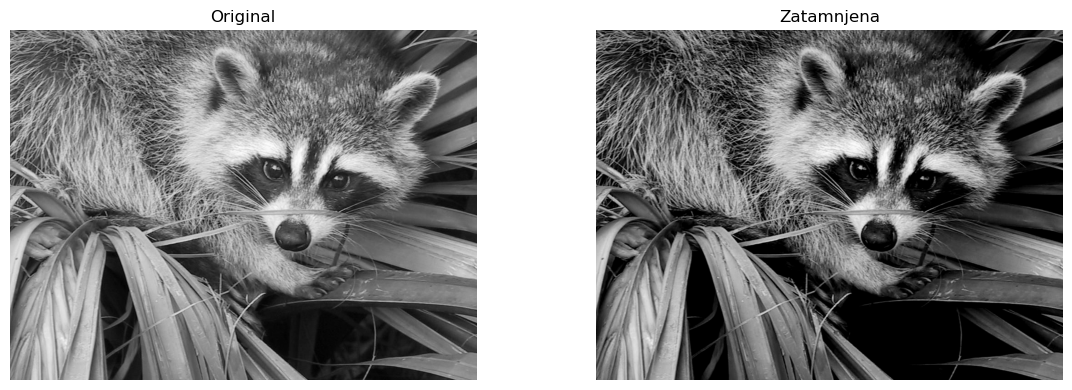

0.9795149690125645
0.9881740960042046
168.4981674931124


In [48]:
rakun_dark = np.clip(rakun_gray - 0.2, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(rakun_gray, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(rakun_dark, cmap='gray')
axes[1].set_title('Zatamnjena')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(matrix_cosine_similarity(rakun_gray, rakun_dark))
print(matrix_cosine_similarity_v2(rakun_gray, rakun_dark))
print(matrix_euclidean_distance(rakun_gray, rakun_dark))

***